# RQ4: What characteristics distinguish different LLMs?

RQ1 showed *whether* LLMs can be told apart. This notebook asks *why*, in
four steps:

1. **Style profile.** Measure ~30 interpretable features per response
   (length, vocabulary, punctuation, formatting, habits) and compare their
   averages across LLMs.
2. **Features-only classifier.** Classify the LLM from these features
   alone, then rank which features and feature groups it relies on.
3. **Removal experiments.** Strip one kind of signal from the text
   (formatting, punctuation, length, opening/closing sentences), retrain
   TF-IDF + Logistic Regression and the TextCNN, and measure the drop.
4. **Indicative n-grams.** The words and symbols most associated with each LLM.

Same data pipeline and question-grouped split as RQ1/RQ2. This notebook is
self-contained.

**How to run.** In Colab, choose *Runtime → Change runtime type → GPU*, then
run all cells top to bottom. Figures and tables are saved to `results/rq4/`.

In [1]:
import copy
import json
import random
import re
import subprocess
import sys
import time
from collections import Counter
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import f_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

In [2]:
@dataclass
class Config:
    # --- Data ---
    dataset_handle: str = "mdsadiqiqbal/txd-22-a-large-scale-benchmark-dataset"
    csv_path: str | None = None
    prompt_col: str = "Question"
    response_col: str = "Answer"
    label_col: str = "Source"
    # TXD-22 also contains human-written and mixed human/AI labels.
    non_llm_label_pattern: str | None = r"(?i)human|ai-generated|ai-refined"

    # --- Class balancing ---
    min_samples_per_class: int = 500
    max_samples_per_class: int | None = 3000

    # --- Splits (fractions of the whole dataset, split by question) ---
    test_size: float = 0.15
    val_size: float = 0.15

    # --- Removal experiments ---
    truncate_words: int = 100

    # --- Text preprocessing (TextCNN) ---
    max_vocab_size: int = 50_000
    min_token_freq: int = 2
    max_seq_len: int = 400

    # --- TextCNN hyperparameters (same as RQ1) ---
    embed_dim: int = 128
    dropout: float = 0.5
    batch_size: int = 64
    epochs: int = 10
    learning_rate: float = 1e-3
    weight_decay: float = 1e-4
    patience: int = 3
    grad_clip: float = 1.0
    cnn_num_filters: int = 128
    cnn_kernel_sizes: tuple[int, ...] = (3, 4, 5)

    # --- Misc ---
    seed: int = 42
    results_dir: str = "results/rq4"


CONFIG = Config()
RESULTS_DIR = Path(CONFIG.results_dir)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


def set_seed(seed: int) -> None:
    """Make runs reproducible across Python, NumPy and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def scores(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "macro_f1": round(f1_score(y_true, y_pred, average="macro"), 4),
    }


set_seed(CONFIG.seed)

Device: cuda


## 1. Load, clean, balance and split the data (same pipeline as RQ1)

In [3]:
def load_raw_dataset(cfg: Config) -> pd.DataFrame:
    """Read the TXD-22 CSV from a local path or download it from Kaggle."""
    if cfg.csv_path:
        csv_file = Path(cfg.csv_path)
    else:
        download_dir = Path(kagglehub.dataset_download(cfg.dataset_handle))
        csv_file = next(download_dir.rglob("*.csv"))
    print(f"Reading {csv_file}")
    # The file contains a few invalid UTF-8 bytes; replace them instead of crashing.
    return pd.read_csv(csv_file, encoding="utf-8", encoding_errors="replace")


def clean_dataset(df: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    columns = [cfg.prompt_col, cfg.response_col, cfg.label_col]
    df = df[columns].dropna().copy()
    for col in columns:
        df[col] = df[col].astype(str).str.strip()
    df = df[df[cfg.response_col].str.len() > 0]

    before = len(df)
    df = df.drop_duplicates(subset=[cfg.response_col, cfg.label_col])
    df = df.drop_duplicates(subset=[cfg.response_col], keep=False)
    print(f"Removed {before - len(df):,} duplicate or ambiguous answers")
    return df.reset_index(drop=True)


def drop_non_llm_labels(df: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    if cfg.non_llm_label_pattern is None:
        return df
    is_non_llm = df[cfg.label_col].str.contains(cfg.non_llm_label_pattern, regex=True)
    print(f"Dropping non-LLM labels: {sorted(df.loc[is_non_llm, cfg.label_col].unique())}")
    return df[~is_non_llm].reset_index(drop=True)


def balance_classes(df: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    counts = df[cfg.label_col].value_counts()
    kept_labels = counts[counts >= cfg.min_samples_per_class].index
    dropped = sorted(set(counts.index) - set(kept_labels))
    if dropped:
        print(f"Dropping classes with < {cfg.min_samples_per_class} samples: {dropped}")
    df = df[df[cfg.label_col].isin(kept_labels)]

    if cfg.max_samples_per_class is not None:
        shuffled = df.sample(frac=1, random_state=cfg.seed)
        df = shuffled.groupby(cfg.label_col).head(cfg.max_samples_per_class)
    return df.reset_index(drop=True)


def grouped_split(
    df: pd.DataFrame, holdout_frac: float, cfg: Config
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split off roughly `holdout_frac` of rows with no question shared between parts."""
    n_splits = max(2, round(1 / holdout_frac))
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=cfg.seed)
    keep_idx, holdout_idx = next(
        splitter.split(df, df[cfg.label_col], groups=df[cfg.prompt_col])
    )
    return df.iloc[keep_idx].reset_index(drop=True), df.iloc[holdout_idx].reset_index(drop=True)


raw_df = load_raw_dataset(CONFIG)
data_df = balance_classes(drop_non_llm_labels(clean_dataset(raw_df, CONFIG), CONFIG), CONFIG)
print(f"Final dataset: {len(data_df):,} answers, {data_df[CONFIG.label_col].nunique()} LLMs")

CLASS_NAMES = sorted(data_df[CONFIG.label_col].unique())
LABEL_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

100%|██████████| 35.1M/35.1M [00:01<00:00, 23.0MB/s]

Extracting files...


Reading /root/.cache/kagglehub/datasets/mdsadiqiqbal/txd-22-a-large-scale-benchmark-dataset/versions/2/TXD-22 A Large-Scale Benchmark Dataset.csv
Removed 48 duplicate or ambiguous answers
Dropping non-LLM labels: ['AI-generated and AI-refined', 'AI-generated and AI-refined and Human-written', 'AI-generated�and Human-written', 'Human written', 'Human-written and AI-refined']
Final dataset: 50,980 answers, 17 LLMs


## 2. Interpretable style features

Counts of punctuation are normalised **per 100 words** so that long answers
do not dominate. Lexical diversity is the type-token ratio of the **first 100
words**, because the raw ratio always falls as texts get longer.

| Group | Kind | Features |
|---|---|---|
| Length | structural | words, characters, sentences, words per sentence |
| Formatting | structural | non-empty lines, blank lines, headings, bullets, numbered items, bold, code, emoji |
| Vocabulary | linguistic | word length, type-token ratio, long-word share, first-person pronouns |
| Punctuation | linguistic | commas, `!`, `?`, `:`, `;`, parentheses, dashes per 100 words |
| Habits | linguistic | opens with "Certainly/Sure…", repeats the question, closes with an offer to help |
| Encoding | dataset artefact | `�` replacement characters from broken text encoding |

The **Encoding** group is not a writing style. If it turns out to matter, it
means some sources' text was collected or stored differently, which is a
dataset artefact worth reporting.

In [4]:
WORD_RE = re.compile(r"\b\w+\b")
SENTENCE_END_RE = re.compile(r"[.!?]+(?=\s|$)")
HEADING_RE = re.compile(r"^\s*#{1,6}\s", re.MULTILINE)
BULLET_RE = re.compile(r"^\s*[-*•]\s", re.MULTILINE)
NUMBERED_RE = re.compile(r"^\s*\d+[.)]\s", re.MULTILINE)
BOLD_RE = re.compile(r"\*\*[^*\n]+\*\*")
INLINE_CODE_RE = re.compile(r"(?<!`)`[^`\n]+`(?!`)")
EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF☀-➿]")
DASH_RE = re.compile(r"—|–| - ")
AFFIRMATION_RE = re.compile(r"^(certainly|sure|absolutely|of course|great question|yes|okay)\b")
OFFER_RE = re.compile(r"let me know|hope (this|that) helps|feel free|if you have any|happy to help")
FIRST_PERSON = {"i", "me", "my", "mine", "i'm", "i've", "i'd", "i'll"}

FEATURE_GROUPS: dict[str, list[str]] = {
    "Length": ["words", "characters", "sentences", "words_per_sentence"],
    "Formatting": [
        "lines", "blank_lines", "headings", "bullet_items", "numbered_items",
        "bold_spans", "code_blocks", "inline_code", "emoji",
    ],
    "Vocabulary": [
        "mean_word_length", "type_token_ratio_100", "long_word_share", "first_person_per_100",
    ],
    "Punctuation": [
        "commas_per_100", "exclamations_per_100", "questions_per_100", "colons_per_100",
        "semicolons_per_100", "parentheses_per_100", "dashes_per_100",
    ],
    "Habits": ["opens_with_affirmation", "echoes_question", "closes_with_offer"],
    "Encoding": ["replacement_chars"],
}
FEATURES = [name for group in FEATURE_GROUPS.values() for name in group]
FEATURE_TO_GROUP = {name: group for group, names in FEATURE_GROUPS.items() for name in names}


def extract_style_features(answer: str, question: str) -> dict[str, float]:
    words = WORD_RE.findall(answer)
    n_words = max(len(words), 1)
    per_100_words = 100 / n_words
    n_sentences = max(len(SENTENCE_END_RE.findall(answer)), 1)
    first_100 = [w.lower() for w in words[:100]]
    lines = answer.splitlines()
    lower = answer.lower()

    return {
        # Length
        "words": len(words),
        "characters": len(answer),
        "sentences": n_sentences,
        "words_per_sentence": len(words) / n_sentences,
        # Formatting
        "lines": sum(1 for line in lines if line.strip()),
        "blank_lines": sum(1 for line in lines if not line.strip()),
        "headings": len(HEADING_RE.findall(answer)),
        "bullet_items": len(BULLET_RE.findall(answer)),
        "numbered_items": len(NUMBERED_RE.findall(answer)),
        "bold_spans": len(BOLD_RE.findall(answer)),
        "code_blocks": answer.count("```") // 2,
        "inline_code": len(INLINE_CODE_RE.findall(answer)),
        "emoji": len(EMOJI_RE.findall(answer)),
        # Vocabulary
        "mean_word_length": float(np.mean([len(w) for w in words])) if words else 0.0,
        "type_token_ratio_100": len(set(first_100)) / len(first_100) if first_100 else 0.0,
        "long_word_share": sum(len(w) >= 8 for w in words) / n_words,
        "first_person_per_100": sum(w.lower() in FIRST_PERSON for w in words) * per_100_words,
        # Punctuation
        "commas_per_100": answer.count(",") * per_100_words,
        "exclamations_per_100": answer.count("!") * per_100_words,
        "questions_per_100": answer.count("?") * per_100_words,
        "colons_per_100": answer.count(":") * per_100_words,
        "semicolons_per_100": answer.count(";") * per_100_words,
        "parentheses_per_100": answer.count("(") * per_100_words,
        "dashes_per_100": len(DASH_RE.findall(answer)) * per_100_words,
        # Habits
        "opens_with_affirmation": float(bool(AFFIRMATION_RE.match(lower))),
        "echoes_question": float(lower.startswith(question.lower()[:40])),
        "closes_with_offer": float(bool(OFFER_RE.search(lower[-250:]))),
        # Encoding artefact
        "replacement_chars": answer.count("�"),
    }


start = time.time()
feature_rows = [
    extract_style_features(answer, question)
    for answer, question in zip(data_df[CONFIG.response_col], data_df[CONFIG.prompt_col])
]
data_df = pd.concat([data_df, pd.DataFrame(feature_rows)[FEATURES]], axis=1)
print(f"Extracted {len(FEATURES)} features for {len(data_df):,} answers "
      f"in {time.time() - start:.0f}s")

Extracted 28 features for 50,980 answers in 41s


## 3. Style profile of each LLM

The heatmap shows each LLM's average feature value as a z-score across LLMs:
red = much higher than the other LLMs, blue = much lower. The raw averages
are saved to `style_profile_by_llm.csv` for exact numbers.

The F-statistic (one-way ANOVA) ranks features by how strongly their values
differ *between* LLMs relative to the variation *within* each LLM.

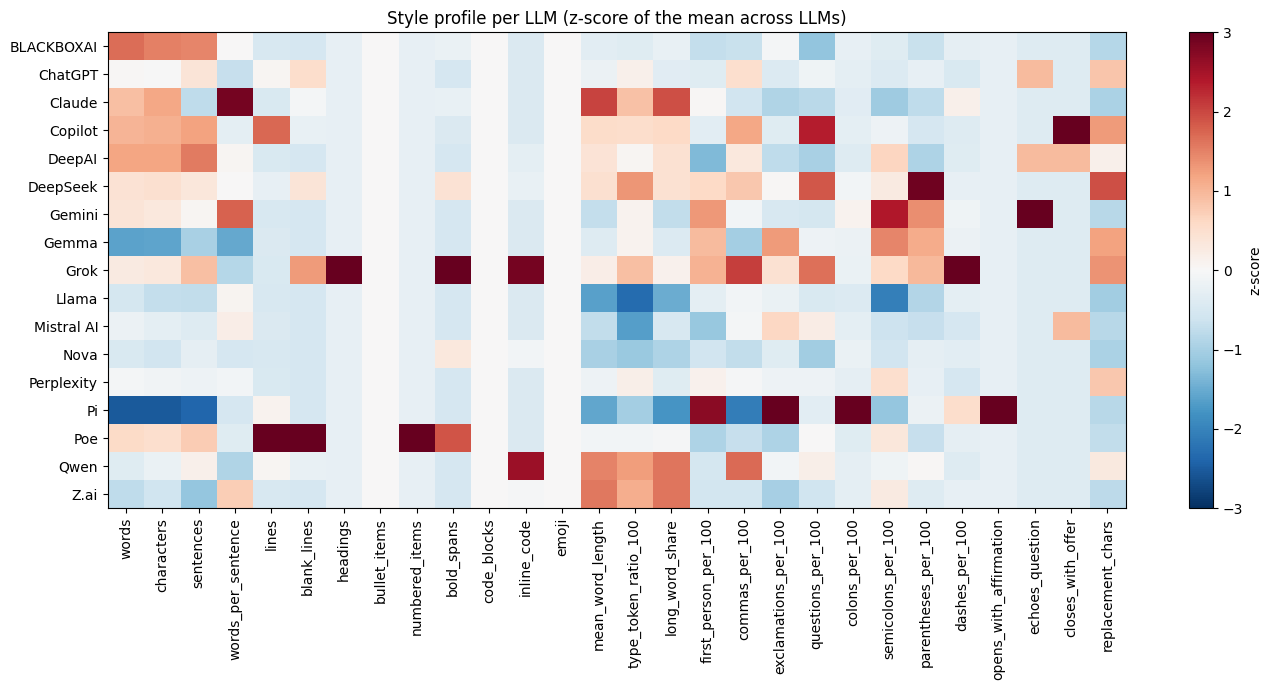

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 7 10 12] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


Features that differ most between LLMs:
             feature       group  anova_F
          characters      Length   3274.9
               words      Length   3214.8
           sentences      Length   2097.0
      colons_per_100 Punctuation   1903.3
type_token_ratio_100  Vocabulary   1062.0
    mean_word_length  Vocabulary    732.9
 parentheses_per_100 Punctuation    685.7
   replacement_chars    Encoding    602.5
     long_word_share  Vocabulary    497.4
      commas_per_100 Punctuation    425.1
  words_per_sentence      Length    409.3
          bold_spans  Formatting    105.4
  semicolons_per_100 Punctuation     49.1
      dashes_per_100 Punctuation     34.1
   questions_per_100 Punctuation     16.6


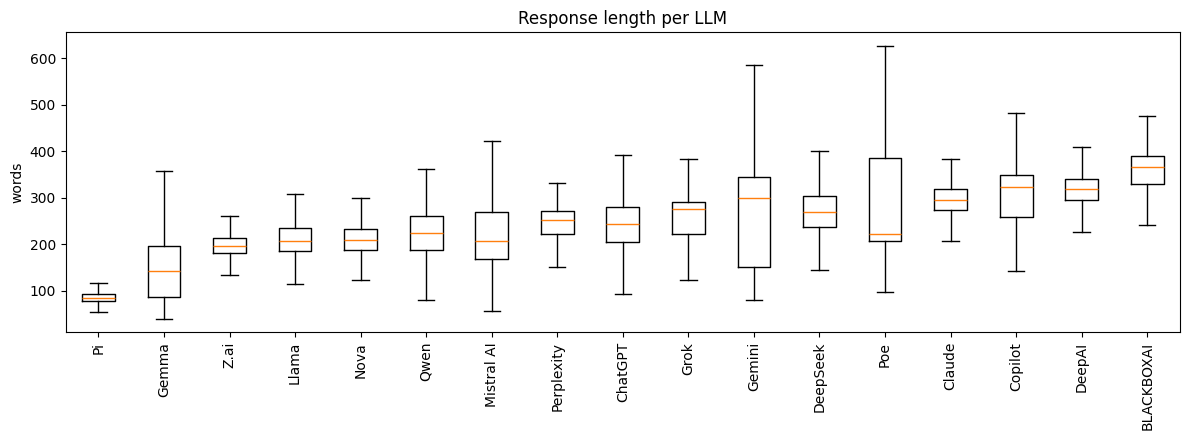

In [5]:
profile = data_df.groupby(CONFIG.label_col)[FEATURES].mean()
profile.round(3).to_csv(RESULTS_DIR / "style_profile_by_llm.csv")

profile_z = (profile - profile.mean()) / profile.std(ddof=0).replace(0, 1)
fig, ax = plt.subplots(figsize=(14, 7))
image = ax.imshow(profile_z.to_numpy(), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90)
ax.set_yticks(range(len(profile_z)), profile_z.index)
ax.set_title("Style profile per LLM (z-score of the mean across LLMs)")
fig.colorbar(image, ax=ax, label="z-score")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "style_profile_heatmap.png", dpi=150)
plt.show()

f_stats, _ = f_classif(data_df[FEATURES].to_numpy(), data_df[CONFIG.label_col])
feature_ranking = pd.DataFrame({
    "feature": FEATURES,
    "group": [FEATURE_TO_GROUP[f] for f in FEATURES],
    "anova_F": np.nan_to_num(f_stats),
}).sort_values("anova_F", ascending=False).round(1)
feature_ranking.to_csv(RESULTS_DIR / "feature_anova_ranking.csv", index=False)
print("Features that differ most between LLMs:")
print(feature_ranking.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4.5))
order = profile["words"].sort_values().index
ax.boxplot(
    [data_df.loc[data_df[CONFIG.label_col] == llm, "words"] for llm in order],
    showfliers=False,
)
ax.set_xticks(range(1, len(order) + 1), order, rotation=90)
ax.set(title="Response length per LLM", ylabel="words")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "response_length_boxplot.png", dpi=150)
plt.show()

## 4. Split (grouped by question, same as RQ1/RQ2)

In [6]:
train_val_df, test_df = grouped_split(data_df, CONFIG.test_size, CONFIG)
train_df, val_df = grouped_split(train_val_df, CONFIG.val_size / (1 - CONFIG.test_size), CONFIG)
assert not set(train_df[CONFIG.prompt_col]) & set(test_df[CONFIG.prompt_col])

y_train = train_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()
y_val = val_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()
y_test = test_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()
for name, split in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:>5}: {len(split):6,} answers")

train: 36,369 answers
  val:  7,296 answers
 test:  7,315 answers


## 5. Can the LLM be identified from style features alone?

* **Gradient boosting** (`HistGradientBoostingClassifier`) captures
  non-linear feature combinations; **Logistic Regression** is a linear check.
* **Permutation importance**: how much test macro-F1 drops when one feature's
  values are shuffled. Bigger drop = the classifier relies on it more.
* **Group ablation**: retrain without each feature group, and with *only*
  that group, to separate structural from linguistic signals.

In [7]:
def train_feature_classifier(features: list[str]) -> HistGradientBoostingClassifier:
    model = HistGradientBoostingClassifier(max_iter=200, random_state=CONFIG.seed)
    return model.fit(train_df[features], y_train)


start = time.time()
boosting = train_feature_classifier(FEATURES)
boosting_scores = scores(y_test, boosting.predict(test_df[FEATURES]))
print(f"Gradient boosting on all {len(FEATURES)} features: {boosting_scores} "
      f"({time.time() - start:.0f}s)")

linear = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
linear.fit(train_df[FEATURES], y_train)
linear_scores = scores(y_test, linear.predict(test_df[FEATURES]))
print(f"Logistic regression on all features: {linear_scores}")
print(f"(Chance level: {1 / len(CLASS_NAMES):.4f})")

Gradient boosting on all 28 features: {'accuracy': 0.5523, 'macro_f1': 0.5463} (13s)
Logistic regression on all features: {'accuracy': 0.4443, 'macro_f1': 0.4286}
(Chance level: 0.0588)


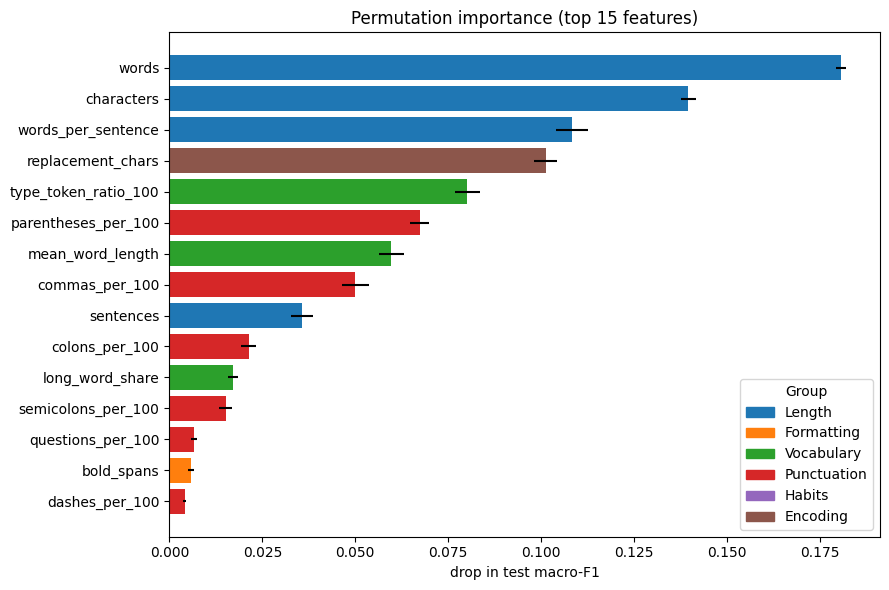

In [8]:
importance = permutation_importance(
    boosting, test_df[FEATURES], y_test, scoring="f1_macro",
    n_repeats=5, random_state=CONFIG.seed, n_jobs=-1,
)
importance_df = pd.DataFrame({
    "feature": FEATURES,
    "group": [FEATURE_TO_GROUP[f] for f in FEATURES],
    "macro_f1_drop": importance.importances_mean,
    "std": importance.importances_std,
}).sort_values("macro_f1_drop", ascending=False).round(4)
importance_df.to_csv(RESULTS_DIR / "permutation_importance.csv", index=False)

top = importance_df.head(15).iloc[::-1]
group_colors = dict(zip(FEATURE_GROUPS, plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["feature"], top["macro_f1_drop"], xerr=top["std"],
        color=[group_colors[g] for g in top["group"]])
ax.set(title="Permutation importance (top 15 features)", xlabel="drop in test macro-F1")
ax.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()],
    labels=list(group_colors), title="Group", loc="lower right",
)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "permutation_importance.png", dpi=150)
plt.show()

In [9]:
group_rows = [{"features used": "all groups", **boosting_scores}]
for group, group_features in FEATURE_GROUPS.items():
    without = [f for f in FEATURES if f not in group_features]
    group_rows.append({
        "features used": f"all except {group}",
        **scores(y_test, train_feature_classifier(without).predict(test_df[without])),
    })
    group_rows.append({
        "features used": f"only {group}",
        **scores(y_test, train_feature_classifier(group_features).predict(test_df[group_features])),
    })

group_ablation = pd.DataFrame(group_rows)
group_ablation["macro_f1_drop"] = (boosting_scores["macro_f1"] - group_ablation["macro_f1"]).round(4)
group_ablation.to_csv(RESULTS_DIR / "feature_group_ablation.csv", index=False)
print(group_ablation.to_string(index=False))

         features used  accuracy  macro_f1  macro_f1_drop
            all groups    0.5523    0.5463         0.0000
     all except Length    0.3617    0.3527         0.1936
           only Length    0.3921    0.3764         0.1699
 all except Formatting    0.5465    0.5400         0.0063
       only Formatting    0.0663    0.0203         0.5260
 all except Vocabulary    0.5203    0.5130         0.0333
       only Vocabulary    0.1653    0.1510         0.3953
all except Punctuation    0.4835    0.4765         0.0698
      only Punctuation    0.2323    0.2243         0.3220
     all except Habits    0.5523    0.5463         0.0000
           only Habits    0.0584    0.0065         0.5398
   all except Encoding    0.5091    0.5023         0.0440
         only Encoding    0.1098    0.0524         0.4939


## 6. Removal experiments on the raw text

Each variant removes one kind of signal from **every** answer (train and
test), then TF-IDF + Logistic Regression and the TextCNN are retrained:

| Variant | What is removed |
|---|---|
| Original | nothing |
| No formatting | Markdown symbols (`#`, `*`, `` ` ``, list markers) and all line breaks |
| No punctuation | every character that is not a letter, digit or space |
| Plain words | both of the above, lower-cased: only the word sequence remains |
| Same length | everything after the first `truncate_words` words (formatting kept) |
| No opening/closing | the first and last sentence (greetings, restated question, sign-offs) |

A large drop means the classifier depended on that signal. Note that "Same
length" only shortens long answers; answers under the limit stay as they are.

The TF-IDF model here uses the same tokeniser as the CNN, so it also sees
punctuation and line breaks (`<nl>`).

In [10]:
LIST_MARKER_RE = re.compile(r"^\s*(?:[-*•]|\d+[.)]|#{1,6})\s+", re.MULTILINE)
MARKDOWN_SYMBOL_RE = re.compile(r"[*_`#]+")
NON_ALNUM_RE = re.compile(r"[^\w\s]")
WHITESPACE_RE = re.compile(r"\s+")
SENTENCE_BOUNDARY_RE = re.compile(r"[.!?:](?=\s)")


def remove_formatting(text: str) -> str:
    text = LIST_MARKER_RE.sub("", text)
    text = MARKDOWN_SYMBOL_RE.sub("", text)
    return WHITESPACE_RE.sub(" ", text).strip()


def remove_punctuation(text: str) -> str:
    return WHITESPACE_RE.sub(" ", NON_ALNUM_RE.sub(" ", text)).strip()


def plain_words(text: str) -> str:
    return remove_punctuation(remove_formatting(text)).lower()


def truncate_to_words(text: str, max_words: int = CONFIG.truncate_words) -> str:
    """Cut after the `max_words`-th word, keeping the original formatting before it."""
    for i, match in enumerate(WORD_RE.finditer(text), start=1):
        if i == max_words:
            return text[: match.end()]
    return text


def remove_opening_and_closing(text: str) -> str:
    """Drop the first sentence and, if there are at least three, the last one too."""
    boundaries = [m.end() for m in SENTENCE_BOUNDARY_RE.finditer(text)]
    if not boundaries:
        return text  # A single sentence: nothing can be removed and still leave text.
    end = boundaries[-1] if len(boundaries) > 1 else len(text)
    return text[boundaries[0]: end].strip() or text


TEXT_VARIANTS = {
    "Original": lambda text: text,
    "No formatting": remove_formatting,
    "No punctuation": remove_punctuation,
    "Plain words": plain_words,
    "Same length": truncate_to_words,
    "No opening/closing": remove_opening_and_closing,
}

# Show each variant on the most heavily formatted answer, where the differences are visible.
formatting_amount = data_df[["headings", "bullet_items", "bold_spans", "blank_lines"]].sum(axis=1)
example = data_df.loc[formatting_amount.idxmax(), CONFIG.response_col]
for name, transform in TEXT_VARIANTS.items():
    print(f"--- {name} ---\n{transform(example)[:400]!r}\n")

--- Original ---
'Plants are the cornerstone of the food industry, providing essential raw materials for nutrition, flavor, and processing while supporting global food security and economic systems. As primary producers, plants supply staple crops like **wheat**, **rice**, and **corn**, which form the basis of diets worldwide, processed into bread, pasta, tortillas, and cereals, delivering carbohydrates, proteins, '

--- No formatting ---
'Plants are the cornerstone of the food industry, providing essential raw materials for nutrition, flavor, and processing while supporting global food security and economic systems. As primary producers, plants supply staple crops like wheat, rice, and corn, which form the basis of diets worldwide, processed into bread, pasta, tortillas, and cereals, delivering carbohydrates, proteins, and micronut'

--- No punctuation ---
'Plants are the cornerstone of the food industry providing essential raw materials for nutrition flavor and processing while suppo

In [11]:
TOKEN_PATTERN = re.compile(r"\n|\w+|[^\w\s]")
NEWLINE_TOKEN = "<nl>"


def tokenize(text: str) -> list[str]:
    text = text.replace("\r\n", "\n").lower()
    return [NEWLINE_TOKEN if tok == "\n" else tok for tok in TOKEN_PATTERN.findall(text)]


class Vocabulary:
    PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"
    PAD_ID, UNK_ID = 0, 1

    def __init__(self, tokenized_texts: list[list[str]], max_size: int, min_freq: int):
        counter = Counter(tok for tokens in tokenized_texts for tok in tokens)
        frequent = [tok for tok, freq in counter.most_common(max_size - 2) if freq >= min_freq]
        self.id_to_token = [self.PAD_TOKEN, self.UNK_TOKEN] + frequent
        self.token_to_id = {tok: i for i, tok in enumerate(self.id_to_token)}

    def __len__(self) -> int:
        return len(self.id_to_token)

    def encode(self, tokens: list[str]) -> list[int]:
        return [self.token_to_id.get(tok, self.UNK_ID) for tok in tokens]


def build_tensor_dataset(
    token_lists: list[list[str]], labels: np.ndarray, vocab: Vocabulary, max_len: int
) -> TensorDataset:
    """Encode token lists as a padded (N, max_len) id matrix plus lengths and labels."""
    token_ids = torch.full((len(token_lists), max_len), Vocabulary.PAD_ID, dtype=torch.long)
    lengths = torch.empty(len(token_lists), dtype=torch.long)
    for row, tokens in enumerate(token_lists):
        ids = vocab.encode(tokens[:max_len]) or [Vocabulary.UNK_ID]
        token_ids[row, : len(ids)] = torch.tensor(ids)
        lengths[row] = len(ids)
    return TensorDataset(token_ids, lengths, torch.tensor(labels, dtype=torch.long))


class TextCNN(nn.Module):
    def __init__(
        self, vocab_size: int, embed_dim: int, num_classes: int,
        num_filters: int, kernel_sizes: tuple[int, ...], dropout: float,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=Vocabulary.PAD_ID)
        self.convs = nn.ModuleList(
            nn.Conv1d(embed_dim, num_filters, kernel_size=k) for k in kernel_sizes
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(num_filters * len(kernel_sizes), num_classes)

    def forward(self, token_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        # Conv1d expects (batch, channels, seq_len).
        embedded = self.embedding(token_ids).transpose(1, 2)
        pooled = [F.relu(conv(embedded)).max(dim=2).values for conv in self.convs]
        return self.classifier(self.dropout(torch.cat(pooled, dim=1)))

In [12]:
def run_epoch(
    model: nn.Module, loader: DataLoader, criterion: nn.Module,
    optimizer: torch.optim.Optimizer | None = None, grad_clip: float | None = None,
) -> tuple[float, np.ndarray, np.ndarray]:
    """One pass over `loader`. Trains if an optimizer is given, else evaluates.

    Returns (mean loss, predictions, true labels).
    """
    is_training = optimizer is not None
    model.train(is_training)
    total_loss, all_preds, all_labels = 0.0, [], []

    with torch.set_grad_enabled(is_training):
        for token_ids, lengths, labels in loader:
            token_ids, labels = token_ids.to(DEVICE), labels.to(DEVICE)
            logits = model(token_ids, lengths)
            loss = criterion(logits, labels)

            if is_training:
                optimizer.zero_grad()
                loss.backward()
                if grad_clip:
                    nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                optimizer.step()

            total_loss += loss.item() * len(labels)
            all_preds.append(logits.argmax(dim=1).cpu())
            all_labels.append(labels.cpu())

    preds = torch.cat(all_preds).numpy()
    true = torch.cat(all_labels).numpy()
    return total_loss / len(true), preds, true


def train_model(
    model: nn.Module, train_loader: DataLoader, val_loader: DataLoader, cfg: Config
) -> tuple[nn.Module, pd.DataFrame, float]:
    """Train with early stopping and return (best model, per-epoch history, seconds)."""
    model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay
    )

    history = []
    best_f1, best_state, epochs_without_improvement = -1.0, None, 0
    start = time.time()

    for epoch in range(1, cfg.epochs + 1):
        epoch_start = time.time()
        train_loss, train_pred, train_true = run_epoch(
            model, train_loader, criterion, optimizer, cfg.grad_clip
        )
        val_loss, val_pred, val_true = run_epoch(model, val_loader, criterion)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_acc": accuracy_score(train_true, train_pred),
            "val_acc": accuracy_score(val_true, val_pred),
            "val_macro_f1": f1_score(val_true, val_pred, average="macro"),
        }
        history.append(row)
        print(f"  epoch {epoch:2d} | train loss {train_loss:.4f} acc {row['train_acc']:.4f} | "
              f"val loss {val_loss:.4f} acc {row['val_acc']:.4f} "
              f"F1 {row['val_macro_f1']:.4f} | {time.time() - epoch_start:.0f}s")

        if row["val_macro_f1"] > best_f1:
            best_f1 = row["val_macro_f1"]
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= cfg.patience:
                print(f"  Early stopping: no improvement for {cfg.patience} epochs.")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), time.time() - start


def train_and_test_cnn(
    train_tokens: list[list[str]], val_tokens: list[list[str]], test_tokens: list[list[str]]
) -> np.ndarray:
    """Train a TextCNN on one text variant and return its test predictions."""
    vocab = Vocabulary(train_tokens, CONFIG.max_vocab_size, CONFIG.min_token_freq)
    datasets = [
        build_tensor_dataset(tokens, labels, vocab, CONFIG.max_seq_len)
        for tokens, labels in [(train_tokens, y_train), (val_tokens, y_val), (test_tokens, y_test)]
    ]
    loader_kwargs = {"batch_size": CONFIG.batch_size, "pin_memory": DEVICE.type == "cuda"}
    train_loader = DataLoader(
        datasets[0], shuffle=True,
        generator=torch.Generator().manual_seed(CONFIG.seed), **loader_kwargs,
    )
    val_loader = DataLoader(datasets[1], shuffle=False, **loader_kwargs)
    test_loader = DataLoader(datasets[2], shuffle=False, **loader_kwargs)

    set_seed(CONFIG.seed)
    model = TextCNN(
        vocab_size=len(vocab), embed_dim=CONFIG.embed_dim, num_classes=len(CLASS_NAMES),
        num_filters=CONFIG.cnn_num_filters, kernel_sizes=CONFIG.cnn_kernel_sizes,
        dropout=CONFIG.dropout,
    )
    model, _, _ = train_model(model, train_loader, val_loader, CONFIG)
    _, test_pred, _ = run_epoch(model, test_loader, nn.CrossEntropyLoss())
    return test_pred

In [13]:
removal_rows = []
original_tfidf = None  # Kept for the n-gram analysis in section 7.

for variant, transform in TEXT_VARIANTS.items():
    print(f"\n########## {variant} ##########")
    texts = {
        name: split[CONFIG.response_col].map(transform).tolist()
        for name, split in [("train", train_df), ("val", val_df), ("test", test_df)]
    }
    tokens = {name: [tokenize(t) for t in split_texts] for name, split_texts in texts.items()}

    start = time.time()
    vectorizer = TfidfVectorizer(
        tokenizer=lambda toks: toks, preprocessor=None, lowercase=False, token_pattern=None,
        ngram_range=(1, 2), max_features=100_000, min_df=2, sublinear_tf=True,
    )
    X_train = vectorizer.fit_transform(tokens["train"])
    log_reg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
    tfidf_scores = scores(y_test, log_reg.predict(vectorizer.transform(tokens["test"])))
    print(f"TF-IDF + LogReg: {tfidf_scores} ({time.time() - start:.0f}s)")
    removal_rows.append({"variant": variant, "model": "TF-IDF + LogReg", **tfidf_scores})
    if variant == "Original":
        original_tfidf = (vectorizer, log_reg)

    cnn_scores = scores(y_test, train_and_test_cnn(tokens["train"], tokens["val"], tokens["test"]))
    print(f"TextCNN: {cnn_scores}")
    removal_rows.append({"variant": variant, "model": "TextCNN", **cnn_scores})


########## Original ##########
TF-IDF + LogReg: {'accuracy': 0.7697, 'macro_f1': 0.7654} (117s)
  epoch  1 | train loss 2.3139 acc 0.2667 | val loss 1.5233 acc 0.5217 F1 0.4979 | 13s
  epoch  2 | train loss 1.6786 acc 0.4376 | val loss 1.2972 acc 0.5857 F1 0.5705 | 10s
  epoch  3 | train loss 1.4488 acc 0.5083 | val loss 1.2414 acc 0.5921 F1 0.5843 | 10s
  epoch  4 | train loss 1.2713 acc 0.5674 | val loss 1.1624 acc 0.6084 F1 0.6015 | 10s
  epoch  5 | train loss 1.1286 acc 0.6158 | val loss 1.0895 acc 0.6401 F1 0.6366 | 10s
  epoch  6 | train loss 1.0072 acc 0.6564 | val loss 1.1074 acc 0.6395 F1 0.6317 | 10s
  epoch  7 | train loss 0.9116 acc 0.6859 | val loss 1.0942 acc 0.6479 F1 0.6439 | 11s
  epoch  8 | train loss 0.8308 acc 0.7116 | val loss 1.1219 acc 0.6419 F1 0.6387 | 11s
  epoch  9 | train loss 0.7558 acc 0.7381 | val loss 1.1596 acc 0.6421 F1 0.6358 | 11s
  epoch 10 | train loss 0.6913 acc 0.7604 | val loss 1.2112 acc 0.6309 F1 0.6247 | 11s
  Early stopping: no improvement 

Test macro-F1 after removing each signal:
model               TF-IDF + LogReg  TextCNN
variant                                     
Original                     0.7654   0.6315
No formatting                0.7633   0.6246
No punctuation               0.7227   0.5751
Plain words                  0.7235   0.5687
Same length                  0.5283   0.4394
No opening/closing           0.7037   0.5718


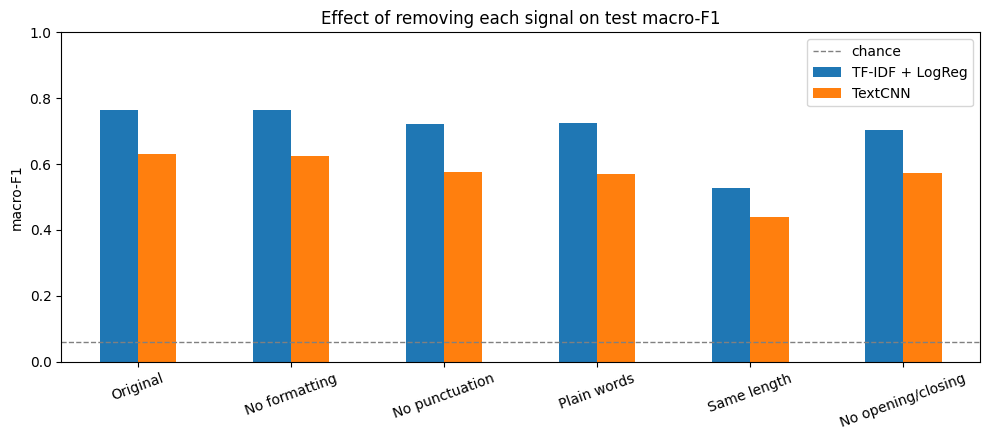

In [14]:
removal_df = pd.DataFrame(removal_rows)
original_f1 = removal_df.query("variant == 'Original'").set_index("model")["macro_f1"]
removal_df["macro_f1_drop"] = (
    removal_df["model"].map(original_f1) - removal_df["macro_f1"]
).round(4)
removal_df.to_csv(RESULTS_DIR / "removal_experiments.csv", index=False)

removal_table = removal_df.pivot(index="variant", columns="model", values="macro_f1")
removal_table = removal_table.loc[list(TEXT_VARIANTS)]
print("Test macro-F1 after removing each signal:")
print(removal_table.to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
removal_table.plot.bar(ax=ax, rot=20)
ax.axhline(1 / len(CLASS_NAMES), color="grey", linestyle="--", linewidth=1, label="chance")
ax.set(title="Effect of removing each signal on test macro-F1", ylabel="macro-F1",
       xlabel="", ylim=(0, 1))
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "removal_experiments.png", dpi=150)
plt.show()

## 7. Most indicative tokens per LLM

The highest-weighted uni/bi-grams of the original-text TF-IDF model for each
LLM. Tokens include punctuation and `<nl>` (line break), so formatting habits
show up here too.

In [15]:
vectorizer, log_reg = original_tfidf
feature_names = vectorizer.get_feature_names_out()
top_ngrams = pd.Series({
    CLASS_NAMES[class_id]: ", ".join(feature_names[np.argsort(weights)[::-1][:10]])
    for class_id, weights in enumerate(log_reg.coef_)
}, name="top n-grams").to_frame()
top_ngrams.to_csv(RESULTS_DIR / "top_ngrams_by_llm.csv")
print(top_ngrams.to_string())

                                                                                                     top n-grams
BLACKBOXAI  in summary, summary ,, summary, , as, . in, $, various, additionally ,, additionally, . additionally
ChatGPT                                     �, � s, . in, helps, also, especially, or, . it, , and, , especially
Claude                                 while, that, through, including, , with, creating, ', where, , while, ' s
Copilot                                  �, . in, such, may, such as, . ultimately, ultimately ,, not, also, � s
DeepAI             overall ,, . overall, . it, overall, . the, because, vital, especially, , especially, it also
DeepSeek                                                         �, ), (, while, ) ,, , while, like, ", ) ., ( e
Gemini                                                                    (, ), ", ', ' s, $, ) ,, highly, an, ;
Gemma                                                                   �, it �, � s, � t, ., s 

## 8. Save run information

**Reading the results for the report**

* **(i) What signals does the classifier use?** Permutation importance
  (section 5), the ANOVA ranking and heatmap (section 3), and the top n-grams
  (section 7).
* **(ii) Linguistic, structural, or both?** Compare "only Length/Formatting"
  (structural) with "only Vocabulary/Punctuation/Habits" (linguistic) in the
  group ablation, and "No formatting" with "Plain words" in the removal
  experiments.
* **(iii) Does removing signals reduce performance?** The `macro_f1_drop`
  columns in `feature_group_ablation.csv` and `removal_experiments.csv`. If
  "Plain words" stays high, the word choice alone carries most of the
  fingerprint.
* If **Encoding** features matter, report them as a dataset-collection
  artefact, not an LLM writing style.

In [16]:
run_info = {
    "config": asdict(CONFIG),
    "classes": CLASS_NAMES,
    "features": FEATURE_GROUPS,
    "split_sizes": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "device": str(DEVICE),
    "features_only": {"gradient_boosting": boosting_scores, "logistic_regression": linear_scores},
    "feature_group_ablation": group_ablation.to_dict(orient="records"),
    "removal_experiments": removal_df.to_dict(orient="records"),
}
(RESULTS_DIR / "rq4_run_info.json").write_text(json.dumps(run_info, indent=2, default=str))
print(f"All outputs saved to {RESULTS_DIR.resolve()}")

All outputs saved to /content/results/rq4
